# Error Analysis — Student Performance

**Author:** Bakai Assylbekov

This notebook extends the evaluation in `04_modeling.ipynb` and looks at *where* the best model (Linear Regression) makes its biggest errors on the test set.

It rebuilds the **same** train/test split and model as `04_modeling.ipynb` (numerical features, 80/20 split, `random_state=42`), so the numbers match that notebook.

Steps:
1. Rebuild the test-set predictions
2. Actual vs. predicted plot (with the largest error labeled)
3. Error summary (overall, G3 = 0 vs. the rest, by grade range and by features)
4. Largest individual errors
5. Where does the model make the biggest errors?

Residual = actual − predicted (negative = the model over-predicts the grade).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from my_modules.error_analysis import (
    plot_actual_vs_predicted,
    error_report,
    top_errors,
    add_errors,
)

## 1. Rebuild the test-set predictions

Same data, features, split and model as `04_modeling.ipynb`.

In [2]:
df_all = pd.read_csv(project_root / "data" / "student-por-clean.csv")

X = df_all.select_dtypes(include=[np.number]).drop(columns=["G3"])
y = df_all["G3"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)

# Test-set table: actual, predicted, and the features used in the error breakdown
df = X_test[["G1", "G2", "absences", "failures"]].copy()
df.insert(0, "y_pred", model.predict(X_test))
df.insert(0, "y_true", y_test)

print("Test set size:", len(df))
df.head()

Test set size: 130


,y_true,y_pred,G1,G2,absences,failures
636,19,18.849525,17,18,4,0
220,12,11.297593,11,11,2,0
594,18,18.877090,18,18,0,0
429,11,11.153591,10,11,5,0
72,11,11.756602,13,11,2,0


## 2. Actual vs. predicted grades

Plot saved to: /Users/bakaiasylbekov/CAP_3764_2026_Fall_Team_1/outputs/visualizations/actual_vs_predicted_annotated.png


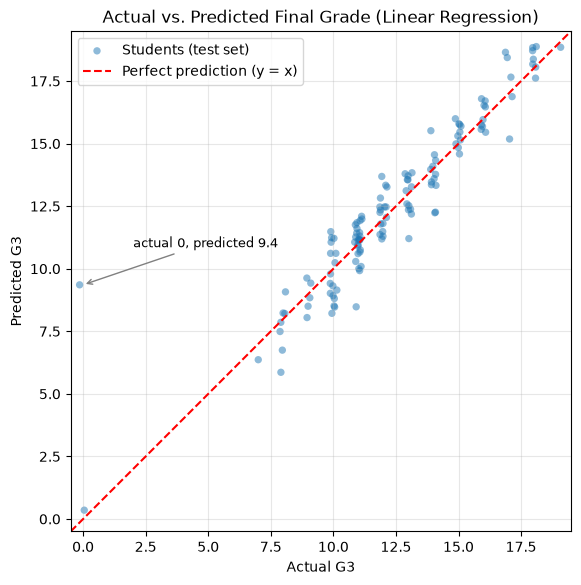

In [3]:
plot_path = project_root / "outputs" / "visualizations" / "actual_vs_predicted_annotated.png"

plot_actual_vs_predicted(
    df["y_true"], df["y_pred"],
    title="Actual vs. Predicted Final Grade (Linear Regression)",
    save_path=plot_path, annotate_top=1,
)
print(f"Plot saved to: {plot_path}")

Points on the red dashed line are predicted exactly. Points far below the line are students the model **over-predicted**. The student with the largest error is labeled.

## 3. Error summary

In [4]:
print(error_report(df))

Overall: MAE=0.73  RMSE=1.17  R2=0.860

MAE: G3 = 0 vs. the rest
          n   MAE
group            
G3 = 0    2  4.85
G3 > 0  128  0.67

MAE by actual-grade bin
            n   MAE
grade_bin          
0           2  4.85
1-7         1  0.64
8-10       29  0.86
11-13      54  0.62
14-16      31  0.56
17-20      13  0.71

MAE by G1
                n   MAE
G1                     
(4.999, 10.0]  41  0.78
(10.0, 12.0]   34  0.91
(12.0, 14.0]   30  0.60
(14.0, 19.0]   25  0.59

MAE by G2
                 n   MAE
G2                      
(-0.001, 10.0]  36  1.04
(10.0, 12.0]    42  0.64
(12.0, 14.0]    22  0.55
(14.0, 18.0]    30  0.63

MAE by absences
                n   MAE
absences               
(-0.001, 2.0]  78  0.83
(2.0, 5.0]     20  0.53
(5.0, 30.0]    32  0.63

MAE by failures
            n   MAE
failures           
0         112  0.64
1          13  0.68
2           1  9.36
3           4  1.41

G3 = 0 rows are 1.5% of the test students but 10.2% of the total absolute error.


## 4. Largest individual errors

In [5]:
cols = ["y_true", "y_pred", "residual", "G1", "G2", "absences", "failures"]
top_errors(df, n=10)[cols].round(2)

,y_true,y_pred,residual,G1,G2,absences,failures
163,0,9.36,-9.36,11,9,0,2
642,11,8.48,2.52,6,9,0,0
518,8,5.86,2.14,8,5,8,1
364,17,15.18,1.82,14,15,2,0
362,13,11.21,1.79,12,11,0,0
557,10,8.22,1.78,7,9,2,3
292,14,12.24,1.76,11,12,2,0
367,14,12.26,1.74,11,12,2,0
39,12,13.69,-1.69,14,13,8,0
344,17,18.65,-1.65,18,18,0,0


## 5. Where does the model make the biggest errors?

The code cell below prints the numbers used in the explanation that follows it.

In [6]:
d = add_errors(df)
zero = d["y_true"] == 0
worst = d.loc[d["abs_error"].idxmax()]
rest = d[~zero]

print(f"Test MAE (all):            {d['abs_error'].mean():.2f}")
print(f"Test MAE (G3 > 0, n={len(rest)}): {rest['abs_error'].mean():.2f}")
print(f"Largest error among G3 > 0: {rest['abs_error'].max():.2f} grade points")
print(f"Students with G3 = 0:       {zero.sum()} ({zero.mean():.1%} of the test set)")
print(f"Worst case: actual {worst['y_true']:.0f}, predicted {worst['y_pred']:.2f}, "
      f"G1={worst['G1']:.0f}, G2={worst['G2']:.0f}, absences={worst['absences']:.0f}")
print(f"Worst case share of total absolute error: {worst['abs_error'] / d['abs_error'].sum():.1%}")
print(f"MAE for G3 > 0 students with G2 <= 9: {rest[rest['G2'] <= 9]['abs_error'].mean():.2f} "
      f"(n={(rest['G2'] <= 9).sum()}) vs. G2 > 9: {rest[rest['G2'] > 9]['abs_error'].mean():.2f} "
      f"(n={(rest['G2'] > 9).sum()})")

Test MAE (all):            0.73
Test MAE (G3 > 0, n=128): 0.67
Largest error among G3 > 0: 2.52 grade points
Students with G3 = 0:       2 (1.5% of the test set)
Worst case: actual 0, predicted 9.36, G1=11, G2=9, absences=0
Worst case share of total absolute error: 9.8%
MAE for G3 > 0 students with G2 <= 9: 0.90 (n=23) vs. G2 > 9: 0.62 (n=105)


**Draft explanation** (numbers from the cell above; check them against the final run before submitting):

The Linear Regression model is accurate for almost every student: for the 128 test students with G3 > 0 the MAE is 0.67 and no error exceeds 2.5 grade points, because G1 and G2 predict G3 closely. The biggest error is one student with a final grade of 0 whom the model predicted at 9.4 (G1 = 11, G2 = 9, no absences, 2 past failures). This single student is 0.8% of the test set but about 10% of the total absolute error. The other student with G3 = 0 was predicted well (0.35) because a G2 of 0 already signals the failure. The model cannot detect students who dropped out after a normal G2, since no numerical feature shows it. Smaller errors concentrate among students with low G2 (≤ 9), where the MAE is higher (0.90 vs. 0.62). Limitation: the test set has only two G3 = 0 students, so these shares are based on very few cases, and the model uses numerical features only.